In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("sales_data_sample.csv", encoding="latin1")
df.head()

,ORDERNUMBER,QUANTITYORDERED,PRICEEACH,ORDERLINENUMBER,SALES,ORDERDATE,STATUS,QTR_ID,MONTH_ID,YEAR_ID,...,ADDRESSLINE1,ADDRESSLINE2,CITY,STATE,POSTALCODE,COUNTRY,TERRITORY,CONTACTLASTNAME,CONTACTFIRSTNAME,DEALSIZE
0,10107,30,95.70,2,2871.00,2/24/2003 0:00,Shipped,1,2,2003,...,897 Long Airport Avenue,NaN,NYC,NY,10022,USA,NaN,Yu,Kwai,Small
1,10121,34,81.35,5,2765.90,5/7/2003 0:00,Shipped,2,5,2003,...,59 rue de l'Abbaye,NaN,Reims,NaN,51100,France,EMEA,Henriot,Paul,Small
2,10134,41,94.74,2,3884.34,7/1/2003 0:00,Shipped,3,7,2003,...,27 rue du Colonel Pierre Avia,NaN,Paris,NaN,75508,France,EMEA,Da Cunha,Daniel,Medium
3,10145,45,83.26,6,3746.70,8/25/2003 0:00,Shipped,3,8,2003,...,78934 Hillside Dr.,NaN,Pasadena,CA,90003,USA,NaN,Young,Julie,Medium
4,10159,49,100.00,14,5205.27,10/10/2003 0:00,Shipped,4,10,2003,...,7734 Strong St.,NaN,San Francisco,CA,NaN,USA,NaN,Brown,Julie,Medium


In [3]:
from sklearn.preprocessing import StandardScaler

In [5]:
X = df[["QUANTITYORDERED", "PRICEEACH", "SALES", "MSRP"]]
print(X.isnull().sum())

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

QUANTITYORDERED    0
PRICEEACH          0
SALES              0
MSRP               0
dtype: int64


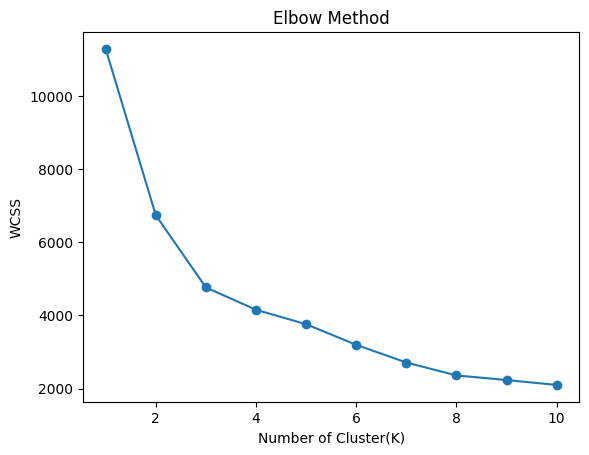

In [7]:
from sklearn.cluster import KMeans
wcss = []

for k in range(1, 11):
    kMeans = KMeans(n_clusters=k, random_state=42)
    kMeans.fit(X_scaled)
    wcss.append(kMeans.inertia_)

plt.plot(range(1, 11), wcss, marker="o")
plt.title("Elbow Method")
plt.xlabel("Number of Cluster(K)")
plt.ylabel("WCSS")
plt.show()

In [10]:
from sklearn.metrics import silhouette_score

kMeans = KMeans(n_clusters=3, random_state=42)
df["Cluster"] = kMeans.fit_predict(X_scaled)

print(df["Cluster"].value_counts())
print("Silhouette score: ", silhouette_score(X_scaled, df["Cluster"]))

Cluster
0    997
1    975
2    851
Name: count, dtype: int64
Silhouette score:  0.3508291135493167


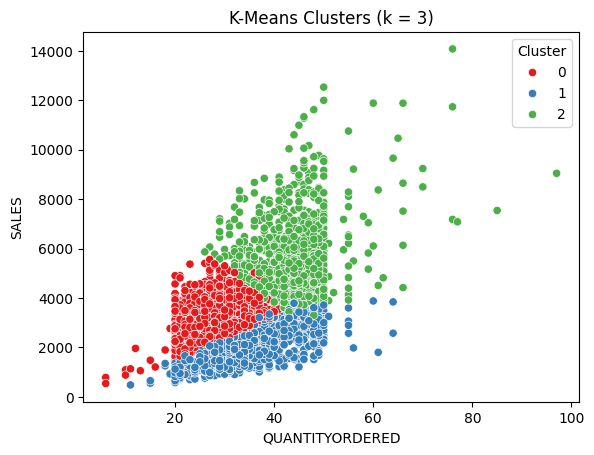

In [14]:
sns.scatterplot(x=df["QUANTITYORDERED"], y=df["SALES"], hue=df["Cluster"], palette="Set1")
plt.title("K-Means Clusters (k = 3)")
plt.show()

In [15]:
df.groupby("Cluster")[["QUANTITYORDERED", "PRICEEACH", "SALES", "MSRP"]].mean()

,QUANTITYORDERED,PRICEEACH,SALES,MSRP
Cluster,,,,
0,27.610832,95.432046,3123.730140,113.229689
1,35.208205,59.551169,2101.076482,64.145641
2,43.726204,97.485229,5722.350564,127.952996


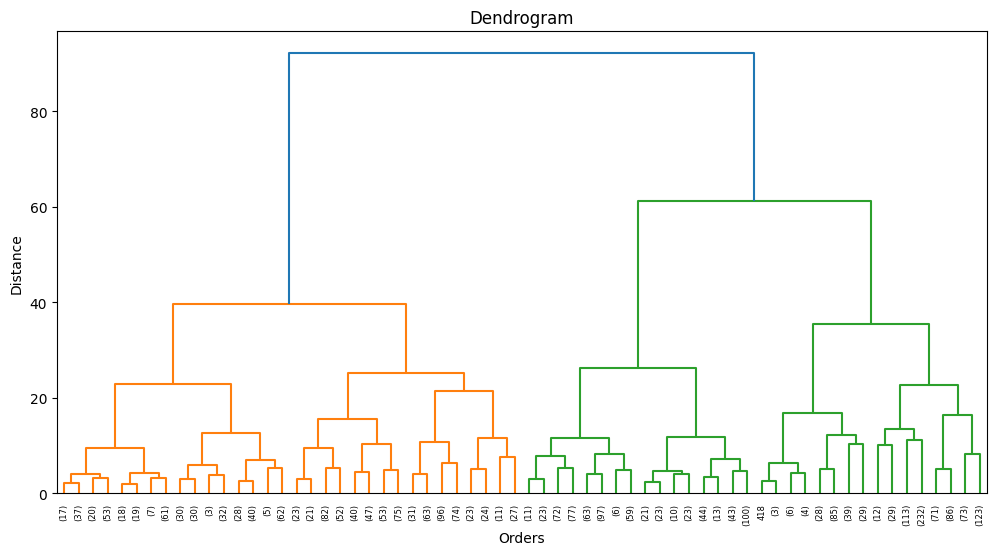

In [16]:
from scipy.cluster.hierarchy import linkage, dendrogram

plt.figure(figsize=(12, 6))
dendrogram(linkage(X_scaled, method="ward"), truncate_mode="level", p=5)
plt.title("Dendrogram")
plt.xlabel("Orders")
plt.ylabel("Distance")
plt.show()